# Lab 3

CNN fine-tuning + color images with Keras framework  
By Alex Horyshevskyi  

### Installing dependencies

In [1]:
%pip install keras numpy scikit-image matplotlib albumentations --quiet
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Bind Keras to PyTorch

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"

### GPU availability check

In [3]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computations will be performed on: {device}")

Using Keras version: 3.13.2
Using PyTorch version: 2.10.0+cu130
Computations will be performed on: cuda


### Load the dataset

In [4]:
from keras.datasets import cifar10


print("Loading CIFAR-10 dataset...")
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Keep image dtype consistent across train/val/test paths.
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)
print("Dataset loaded successfully.")

# Canonical integer labels for display/splits.
y_train_ids = y_train.squeeze().astype("int64")
y_test_ids = y_test.squeeze().astype("int64")
assert y_train_ids.shape == (50000,)
assert y_test_ids.shape == (10000,)

print("Encoding categorical labels as one-hot vectors...")
y_train_encoded = keras.utils.to_categorical(y_train_ids, num_classes=10)
y_test_encoded = keras.utils.to_categorical(y_test_ids, num_classes=10)
assert y_train_encoded.shape == (50000, 10)
assert y_test_encoded.shape == (10000, 10)
print("Labels encoded successfully.")

CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

print(f"""X_train shape: {x_train.shape}; type: {type(x_train)}
Y_train_ids shape: {y_train_ids.shape}, type: {type(y_train_ids)}
Y_train_encoded shape: {y_train_encoded.shape}, type: {type(y_train_encoded)}
X_test shape: {x_test.shape}, type: {type(x_test)}
Y_test_ids shape: {y_test_ids.shape}, type: {type(y_test_ids)}
Y_test_encoded shape: {y_test_encoded.shape}, type: {type(y_test_encoded)}""")

Loading CIFAR-10 dataset...
Dataset loaded successfully.
Encoding categorical labels as one-hot vectors...
Labels encoded successfully.
X_train shape: (50000, 32, 32, 3); type: <class 'numpy.ndarray'>
Y_train_ids shape: (50000,), type: <class 'numpy.ndarray'>
Y_train_encoded shape: (50000, 10), type: <class 'numpy.ndarray'>
X_test shape: (10000, 32, 32, 3), type: <class 'numpy.ndarray'>
Y_test_ids shape: (10000,), type: <class 'numpy.ndarray'>
Y_test_encoded shape: (10000, 10), type: <class 'numpy.ndarray'>


### Sample an image & visualize it

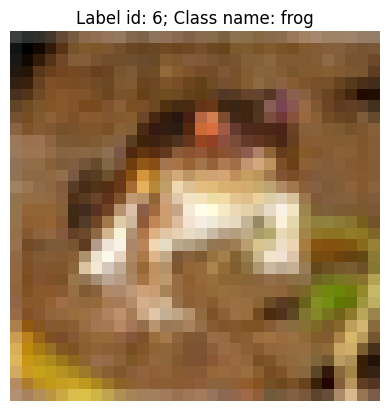

In [5]:
import matplotlib.pyplot as plt


index = 0
sample_label_id = int(y_train_ids[index])
sample_class_name = CLASS_NAMES[sample_label_id]

img = plt.imshow(x_train[index].astype("uint8"))
plt.title(f"Label id: {sample_label_id}; Class name: {sample_class_name}")
plt.axis("off")
plt.show()

### Define image transformer

In [6]:
from torch.utils.data import Dataset
import albumentations as A
import numpy as np


class TransformedDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray, augment: bool = False):
        self.X = X
        self.y = y
        self.augment = augment
        self.transform = A.Compose([
            A.Rotate(limit=15, p=0.2),
            A.Affine(scale=(0.9, 1.1), p=0.2),
            A.HorizontalFlip(p=0.3),
            A.ColorJitter(
                brightness=0.15,
                contrast=0.15,
                saturation=0.15,
                hue=0.05,
                p=0.2,
            ),
        ])

    def __getitem__(self, idx: int):
        # Albumentations color transforms expect uint8 or [0, 1] floats.
        x_uint8 = self.X[idx].astype(np.uint8, copy=False)
        y = self.y[idx].astype(np.float32, copy=False)

        if self.augment:
            augmented = self.transform(image=x_uint8)
            return augmented["image"].astype(np.float32, copy=False), y

        return x_uint8.astype(np.float32, copy=False), y

    def __len__(self):
        return len(self.X)

### Neural network factory

In [ ]:
from collections.abc import Sequence

from dataclasses import dataclass, field

from keras import Sequential
from keras import losses, optimizers, regularizers
from keras.layers import (
    BatchNormalization,
    GlobalAvgPool2D,
    Conv2D,
    Dense,
    Dropout,
    Flatten,
    Input,
    Layer,
    MaxPool2D,
    ReLU,
    Rescaling,
)


@dataclass
class ConvBlockConfig:
    filters: int
    kernel_size: tuple[int, int]
    pool_size: tuple[int, int] | None = (2, 2)  # None = skip pooling
    dropout: float = 0.25
    l2: float = 1e-4


@dataclass
class FullyConnectedConfig:
    units: int
    dropout: float = 0.5
    l2: float = 1e-4


@dataclass
class ModelConfig:
    convolve_blocks: list[ConvBlockConfig]
    fully_connected_blocks: list[FullyConnectedConfig]
    optimizer: str | optimizers.Optimizer = "adam"
    loss: str | losses.Loss = "categorical_crossentropy"
    metrics: list[str] = field(default_factory=lambda: ["accuracy"])


def convolve_block(cfg: ConvBlockConfig) -> Sequence[Layer]:
    regularizer = regularizers.L2(cfg.l2) if cfg.l2 > 0 else None
    layers = [
        Conv2D(
            filters=cfg.filters,
            kernel_size=cfg.kernel_size,
            padding="same",
            kernel_regularizer=regularizer,
        ),
        BatchNormalization(),
        ReLU(),
    ]
    if cfg.pool_size is not None:
        layers.append(MaxPool2D(pool_size=cfg.pool_size))
    if cfg.dropout > 0:
        layers.append(Dropout(cfg.dropout))
    return layers


def fully_connected_block_layers(cfg: FullyConnectedConfig) -> Sequence[Layer]:
    regularizer = regularizers.L2(cfg.l2) if cfg.l2 > 0 else None
    layers = [
        Dense(units=cfg.units, activation="relu", kernel_regularizer=regularizer),
    ]
    if cfg.dropout > 0:
        layers.append(Dropout(cfg.dropout))
    return layers


def construct_model(cfg: ModelConfig) -> Sequential:
    convolve_layers = [
        layer
        for block in cfg.convolve_blocks
        for layer in convolve_block(block)
    ]

    fully_connected_layers = [
        layer
        for block in cfg.fully_connected_blocks
        for layer in fully_connected_block_layers(block)
    ]

    model = Sequential(
        [
            Input(shape=(32, 32, 3)),
            Rescaling(1.0 / 255),
            *convolve_layers,
            Flatten(),
            *fully_connected_layers,
            # GlobalAvgPool2D(), # try to experiment with the window size
            Dense(10, activation="softmax"),
        ]
    )

    model.compile(
        optimizer=cfg.optimizer,
        loss=cfg.loss,
        metrics=cfg.metrics,
    )
    return model

### Train loop

In [8]:
from keras.callbacks import Callback, EarlyStopping, History, ReduceLROnPlateau
from keras.models import Sequential
from torch.utils.data import DataLoader


def train_model(
    model: Sequential,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int = 10,
    batch_size: int = 128,
    callbacks: list[Callback] | None = None,
) -> History:
    if callbacks is None:
        callbacks = [
            ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
            ),
            EarlyStopping(
                monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
            ),
        ]

    history = model.fit(
        train_loader,
        validation_data=val_loader,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
    )
    return history

### Evaluate the model

In [9]:
from keras.callbacks import History
from keras.models import Sequential
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec
from sklearn.model_selection import train_test_split
from datetime import datetime


def evaluate_model(model: Sequential, eval_loader: DataLoader):
    loss, accuracy = model.evaluate(eval_loader)
    return loss, accuracy


def plot_model(
    history: History,
    predictions: np.ndarray | None = None,
    accuracy: float | None = None,
    X_test_images: np.ndarray | None = None,
    y_test_labels: np.ndarray | None = None,
):
    print("Plotting training history and predictions...")
    print(
        f"Final Test Accuracy: {accuracy:.4f}"
        if accuracy is not None
        else "Test Accuracy not available."
    )

    _, ax = (
        plt.subplots(2, 2, figsize=(15, 10))
        if predictions is not None
        else plt.subplots(1, 2, figsize=(15, 5), squeeze=False)
    )

    ax[0, 0].plot(history.history["accuracy"])
    ax[0, 0].plot(history.history["val_accuracy"])
    ax[0, 0].set_title("Model accuracy")
    ax[0, 0].set_ylabel("Accuracy")
    ax[0, 0].set_xlabel("Epoch")
    ax[0, 0].legend(["Train", "Validation"], loc="upper left")

    ax[0, 1].plot(history.history["loss"])
    ax[0, 1].plot(history.history["val_loss"])
    ax[0, 1].set_title("Model loss")
    ax[0, 1].set_ylabel("Loss")
    ax[0, 1].set_xlabel("Epoch")
    ax[0, 1].legend(["Train", "Validation"], loc="upper left")

    if predictions is not None:
        ax[1, 0].hist(predictions, bins=np.arange(-0.5, 10.5, 1), rwidth=0.8)
        ax[1, 0].set_title("Predicted class distribution")
        ax[1, 0].set_xlabel("Class")
        ax[1, 0].set_ylabel("Frequency")

        ax[1, 1].axis("off")

        if X_test_images is not None and len(X_test_images) == len(predictions):
            sample_size = min(5, len(predictions))
            generator = np.random.default_rng(int(datetime.now().timestamp()))
            sample_indices = generator.choice(
                len(predictions), size=sample_size, replace=False
            )
            sample_images = X_test_images[sample_indices]
            sample_labels = predictions[sample_indices]
            sample_true_labels = (
                y_test_labels[sample_indices]
                if y_test_labels is not None
                else [None] * sample_size
            )

            gs = GridSpecFromSubplotSpec(
                1, sample_size, subplot_spec=ax[1, 1].get_subplotspec()
            )
            for idx, (image, label, true_label) in enumerate(
                zip(sample_images, sample_labels, sample_true_labels)
            ):
                sub_ax = plt.subplot(gs[idx])
                sub_ax.imshow(image.astype("uint8"))
                if true_label is None:
                    sub_ax.set_title(f"Pred: {CLASS_NAMES[label]}")
                else:
                    sub_ax.set_title(
                        f"Pred: {CLASS_NAMES[label]}\nTrue: {CLASS_NAMES[int(true_label)]}"
                    )
                sub_ax.axis("off")

    plt.tight_layout()
    plt.show()


def test_model(
    model: Sequential, X_test: np.ndarray, y_test: np.ndarray | None = None
) -> tuple[np.ndarray, float | None]:
    predictions = model.predict(X_test)
    predicted_classes = np.argmax(predictions, axis=1)

    accuracy = None
    if y_test is not None:
        true_classes = np.argmax(y_test, axis=1)
        accuracy = np.mean(predicted_classes == true_classes)

    return predicted_classes, accuracy


def run_model(
    model: Sequential,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray | None = None,
    epochs: int = 30,
    batch_size: int = 128,
    name: str | None = None,
):
    print(f"Running model with epochs={epochs}, batch_size={batch_size}")

    y_train_ids = np.argmax(y_train, axis=1)
    X_train_f, X_val, y_train_f, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42, stratify=y_train_ids
    )

    # 1. Create Datasets
    train_dataset = TransformedDataset(X_train_f, y_train_f, augment=True)
    val_dataset = TransformedDataset(X_val, y_val, augment=False)  # No augment on val!

    # 2. Create PyTorch DataLoaders
    # num_workers=2 speeds up augmentation on the CPU while the GPU trains
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=2
    )
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    history = train_model(
        model,
        train_loader,
        val_loader,
        epochs=epochs,
        batch_size=batch_size,
    )

    val_loss, val_accuracy = evaluate_model(model, val_loader)
    print(
        f"Final Validation Loss: {val_loss:.4f}, Final Validation Accuracy: {val_accuracy:.4f}"
    )

    predictions, test_accuracy = test_model(model, X_test, y_test)
    true_classes = np.argmax(y_test, axis=1) if y_test is not None else None
    plot_model(history, predictions, test_accuracy, X_test, true_classes)

    full_name = (
        f"{name}_cifar10_model.keras"
        if name
        else f"cifar10_model_{datetime.now().timestamp()}.keras"
    )
    model.save(full_name)
    print(f"Model saved as: {full_name}")

### Test the model on my images

In [30]:
from skimage.io import imread
from skimage.transform import resize
import matplotlib.pyplot as plt
import numpy as np
from os import path, listdir


def predict_custom_images(model, image_paths: list[str]):
    original_images = []
    resized_images = []
    
    for p in image_paths:
        img = imread(p)
        original_images.append(img)
        
        # We need them to stay 0-255 so Rescaling(1./255) layer works correctly
        img_resized = resize(img, (32, 32), anti_aliasing=True, preserve_range=True)
        resized_images.append(np.asarray(img_resized, dtype=np.float32))

    X_custom = np.stack(resized_images, axis=0)
    
    predictions, _ = test_model(model, X_custom)

    n_images = len(image_paths)
    _, axes = plt.subplots(2, n_images, figsize=(3 * n_images, 6))
    
    # Handle the edge case if there is only 1 image in the folder
    if n_images == 1:
        axes = np.expand_dims(axes, axis=1)

    for idx, (p, pred) in enumerate(zip(image_paths, predictions)):
        file_name = path.basename(p)
        predicted_class = CLASS_NAMES[pred]
        
        # Row 1: Original High-Res Image
        ax_orig = axes[0, idx]
        ax_orig.imshow(original_images[idx])
        ax_orig.set_title(f"{file_name}\nOriginal")
        ax_orig.axis("off")
        
        # Row 2: 32x32 Downgraded Image
        ax_res = axes[1, idx]
        # Cast back to uint8 for matplotlib visualization
        ax_res.imshow(resized_images[idx].astype("uint8"))
        ax_res.set_title(f"Model Vision (32x32)\nPred: {predicted_class}")
        ax_res.axis("off")
        
    plt.tight_layout()
    plt.show()

eval_images_path = "./images"
eval_image_paths = [
    path.join(eval_images_path, fname)
    for fname in listdir(eval_images_path)
    if path.isfile(path.join(eval_images_path, fname))
]
print(f"Found {len(eval_image_paths)} images for evaluation:")
for img_path in eval_image_paths:
    print(f" - {img_path}")

Found 10 images for evaluation:
 - ./images/airplane.jpeg
 - ./images/automobile.jpeg
 - ./images/bird.jpg
 - ./images/cat.jpg
 - ./images/deer.jpeg
 - ./images/dog.jpg
 - ./images/frog.jpeg
 - ./images/horse.jpg
 - ./images/ship.jpeg
 - ./images/truck.jpg


### Construct the model as in the guide

In [10]:
guide_model_config = ModelConfig(
    convolve_blocks=[
        ConvBlockConfig(32, (5, 5)),
        ConvBlockConfig(64, (5, 5)),
    ],
    fully_connected_blocks=[
        FullyConnectedConfig(1000, dropout=0.5),
        FullyConnectedConfig(500, dropout=0.5),
        FullyConnectedConfig(250, dropout=0),
    ],
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
guide_model = construct_model(guide_model_config)

### Run the loop for the guide model

Running model with epochs=30, batch_size=128
Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 78ms/step - accuracy: 0.3327 - loss: 2.0333 - val_accuracy: 0.3955 - val_loss: 1.9768 - learning_rate: 0.0010
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 118ms/step - accuracy: 0.4329 - loss: 1.7461 - val_accuracy: 0.4248 - val_loss: 1.7399 - learning_rate: 0.0010
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.4755 - loss: 1.5996 - val_accuracy: 0.4991 - val_loss: 1.5401 - learning_rate: 0.0010
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 118ms/step - accuracy: 0.5178 - loss: 1.4758 - val_accuracy: 0.6015 - val_loss: 1.3116 - learning_rate: 0.0010
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - accuracy: 0.5476 - loss: 1.3933 - val_accuracy: 0.5798 - val_loss: 1.3405 - learning_rate: 0.0010
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 91ms/step - accuracy: 0.5727 - loss: 1.3218 - val_accuracy: 0.6099 - val_loss: 1.2906 - learning_rate: 0.0010
Epoch 7/30
313/313 ━━━━━━━━━

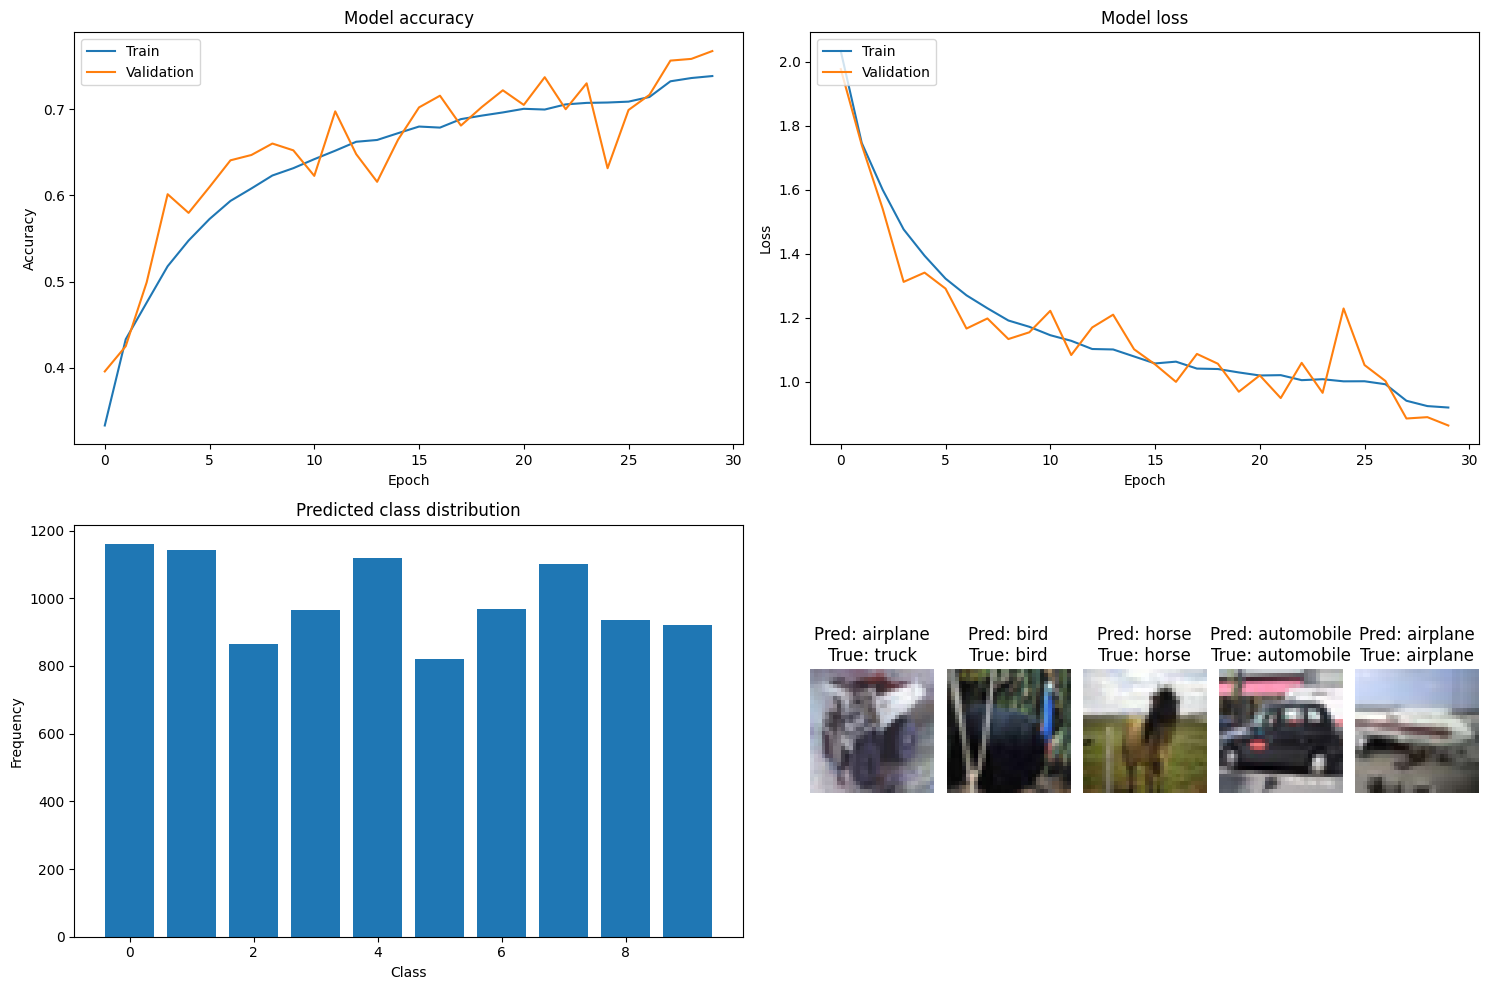

Model saved as: guide_cifar10_model.keras


In [12]:
run_model(
    model=guide_model,
    X_train=x_train,
    y_train=y_train_encoded,
    X_test=x_test,
    y_test=y_test_encoded,
    epochs=30,
    name="guide",
)

### Evaluate the guide model on my images

Loading the guide model and predicting on custom images...
Predicting on custom images...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


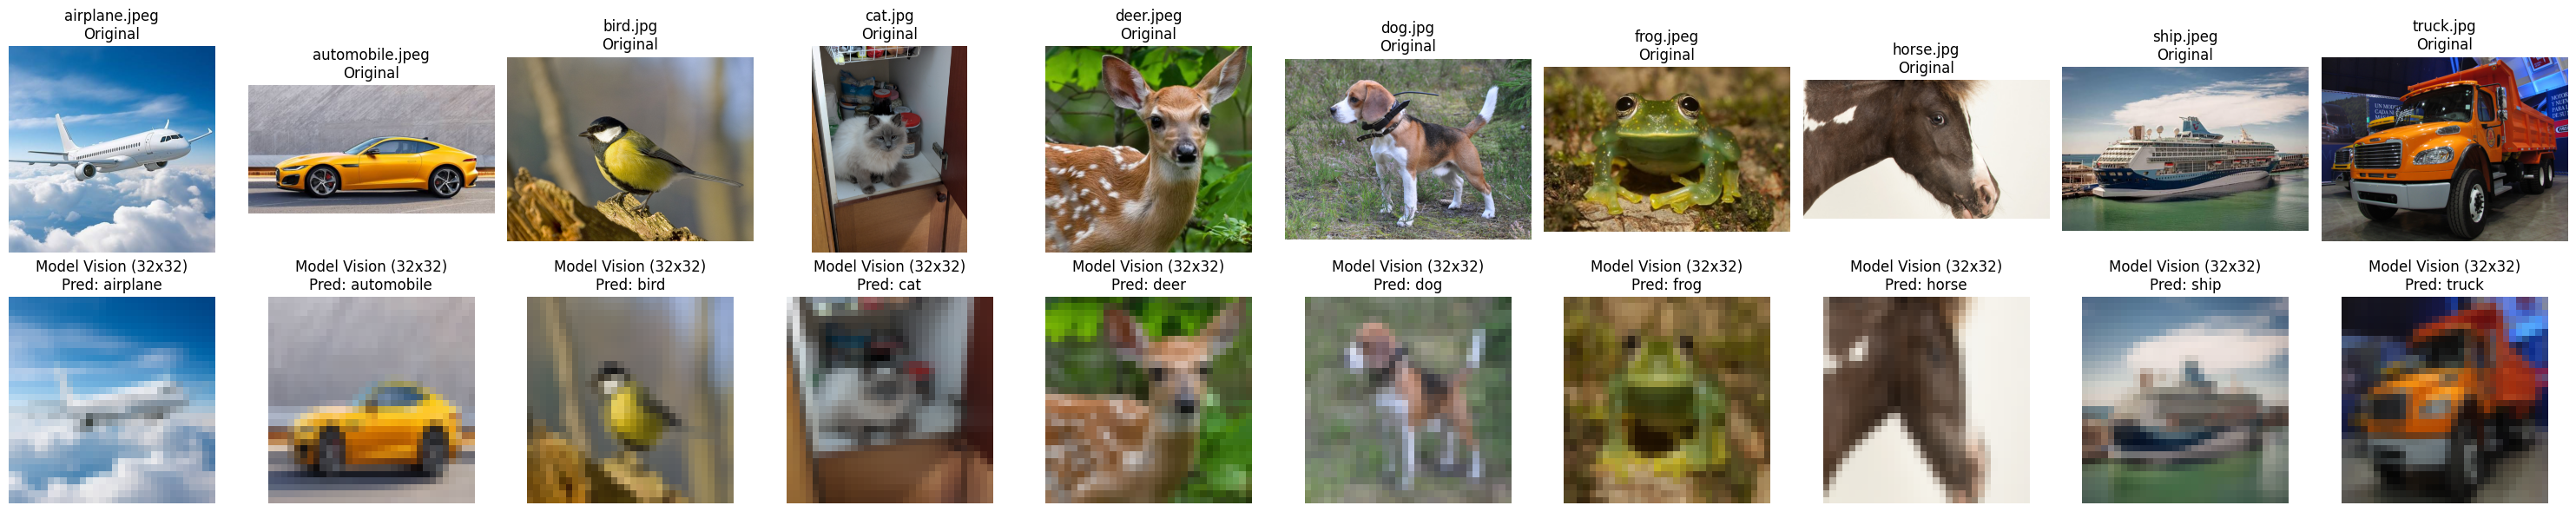

In [31]:
from keras.models import load_model


print("Loading the guide model and predicting on custom images...")
restored_guide_model = load_model("guide_cifar10_model.keras")
print("Predicting on the images...")
predict_custom_images(restored_guide_model, eval_image_paths)

### Construct the custom model with better layers

In [ ]:
custom_model_config = ModelConfig(
    convolve_blocks=[
        ConvBlockConfig(64, (5, 5), dropout=0),
        ConvBlockConfig(128, (3, 3), dropout=0.1),
        ConvBlockConfig(256, (3, 3), dropout=0.2),
        ConvBlockConfig(512, (3, 3), dropout=0.3),
    ],
    fully_connected_blocks=[
        FullyConnectedConfig(128, dropout=0.5),
    ],
    optimizer=optimizers.AdamW(weight_decay=1e-4),
    loss=losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"],
)
custom_model = construct_model(custom_model_config)

### Run the custom model

Running model with epochs=100, batch_size=128
Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.2234 - loss: 2.2230 - val_accuracy: 0.1079 - val_loss: 2.6562 - learning_rate: 0.0010
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.3120 - loss: 1.9985 - val_accuracy: 0.3957 - val_loss: 1.9011 - learning_rate: 0.0010
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.3478 - loss: 1.9195 - val_accuracy: 0.4609 - val_loss: 1.7715 - learning_rate: 0.0010
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.3787 - loss: 1.8667 - val_accuracy: 0.3781 - val_loss: 1.9103 - learning_rate: 0.0010
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.3983 - loss: 1.8279 - val_accuracy: 0.5046 - val_loss: 1.7151 - learning_rate: 0.0010
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.4332 - loss: 1.7929 - val_accuracy: 0.6304 - val_loss: 1.5795 - learning_rate: 0.0010
Epoch 7/100
313/313 ━━━━

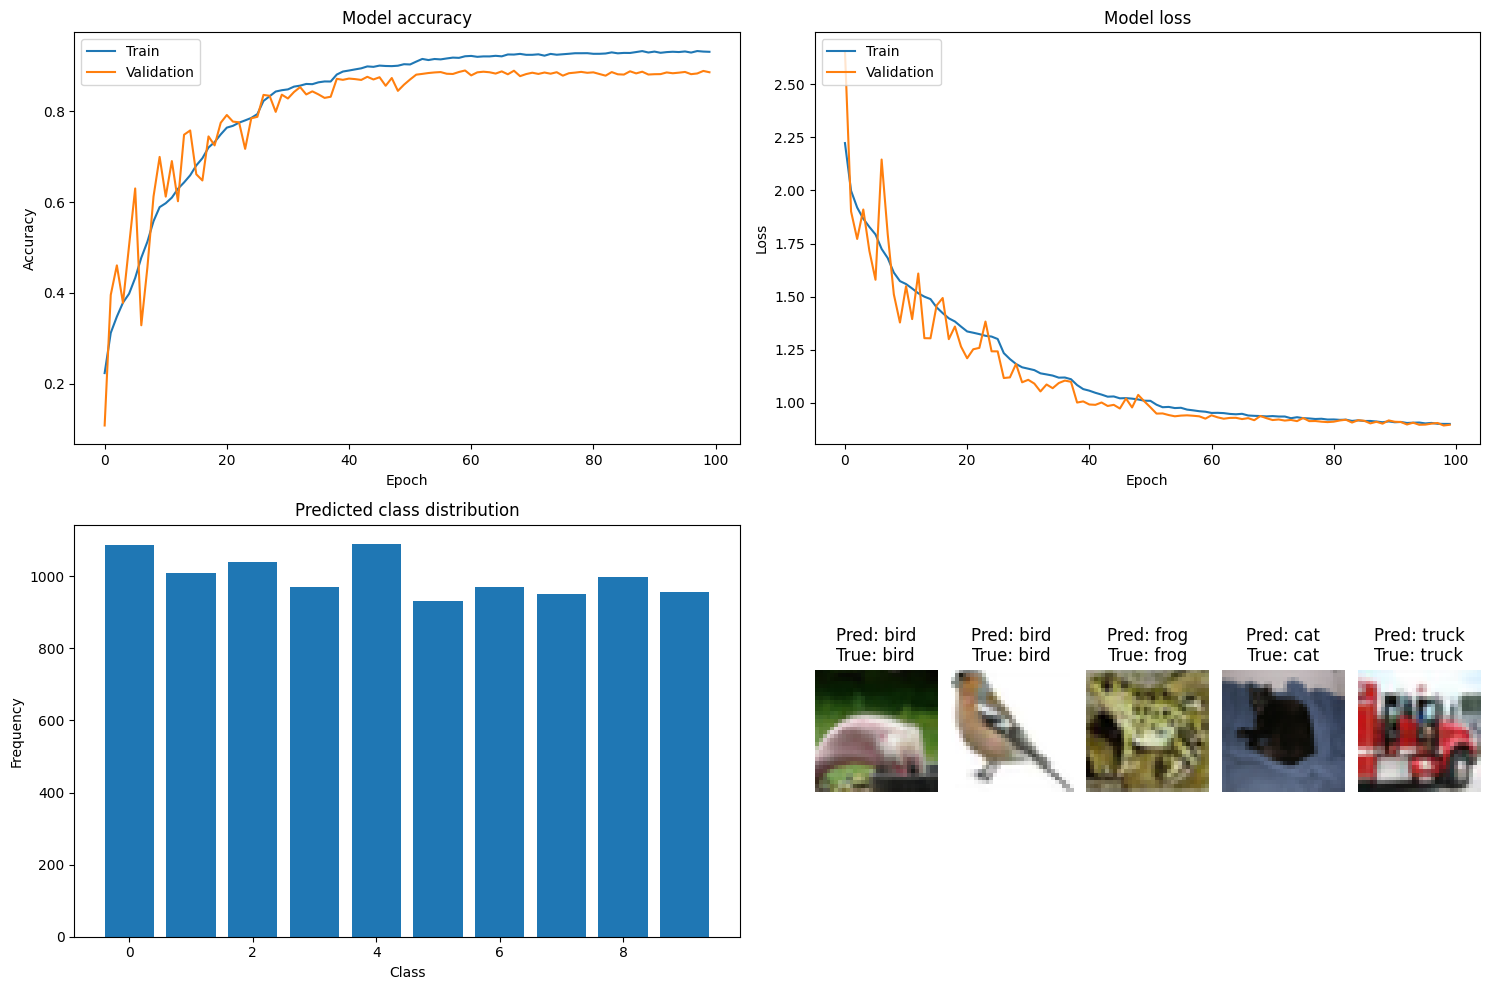

Model saved as: custom_cifar10_model.keras


In [ ]:
run_model(
    model=custom_model,
    X_train=x_train,
    y_train=y_train_encoded,
    X_test=x_test,
    y_test=y_test_encoded,
    epochs=100,
    name="custom",
)

### Evaluate the custom model on my images

Loading the custom model and predicting on custom images...
Predicting on the images...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


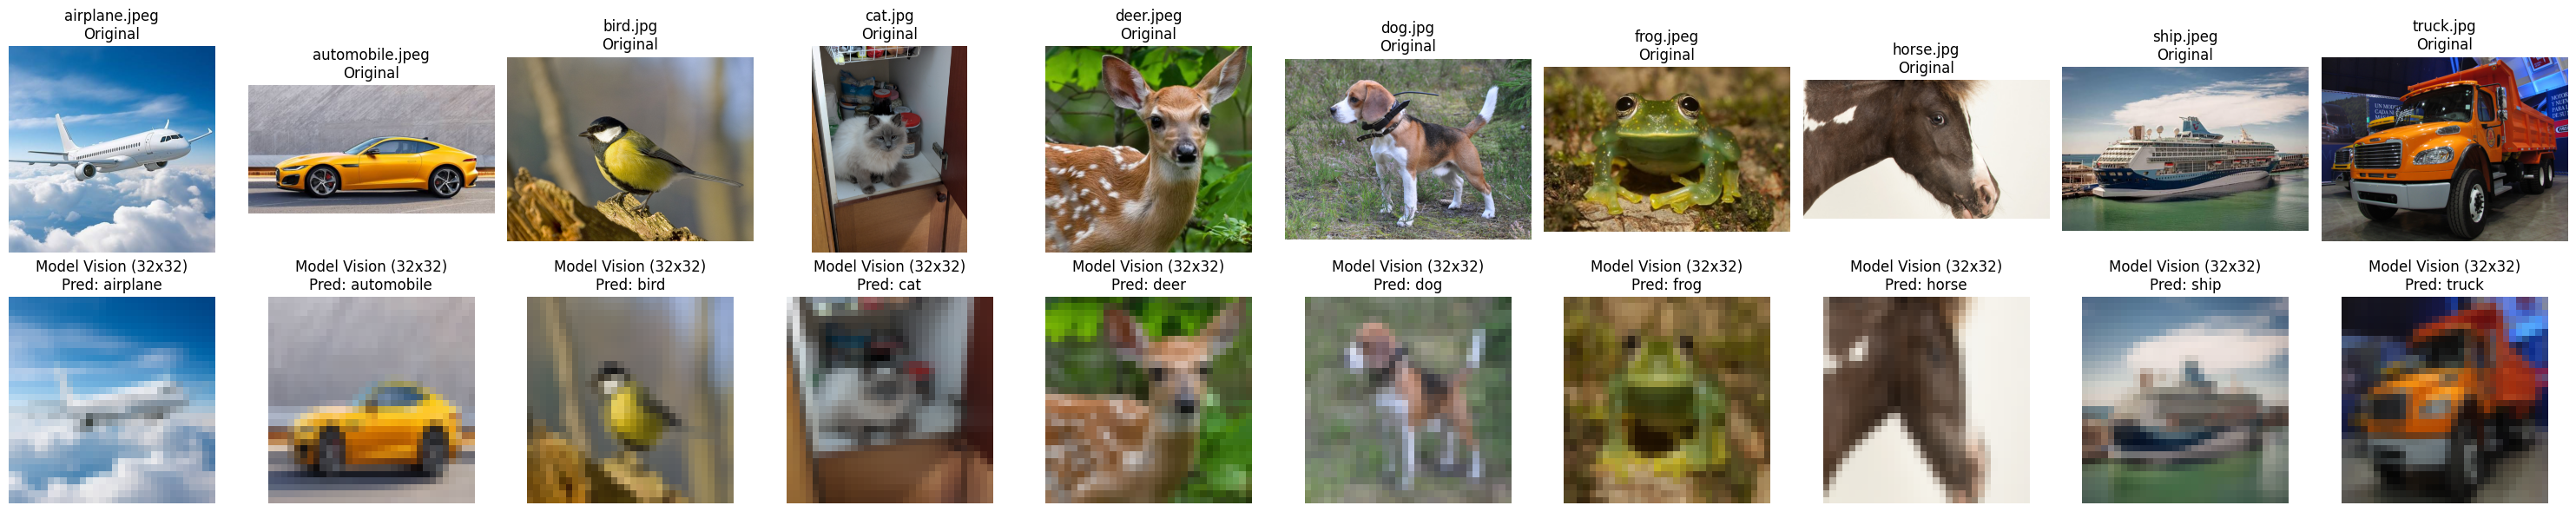

In [33]:
from keras.models import load_model


print("Loading the custom model and predicting on custom images...")
restored_custom_model = load_model("guide_cifar10_model.keras")
print("Predicting on the images...")
predict_custom_images(restored_custom_model, eval_image_paths)